In [1]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


In [3]:

# Generate reproducible random data
rng = np.random.default_rng(42)
#500 rows and 3 columns
X = rng.normal(size=(500, 3))

print(X[:5])


[[ 0.30471708 -1.03998411  0.7504512 ]
 [ 0.94056472 -1.95103519 -1.30217951]
 [ 0.1278404  -0.31624259 -0.01680116]
 [-0.85304393  0.87939797  0.77779194]
 [ 0.0660307   1.12724121  0.46750934]]


In [4]:

# Create target values using a linear relationship
noise = rng.normal(0, 0.1, size=500)

y = 2*X[:, 0] - 3*X[:, 1] + X[:, 2] + noise

print(y.shape)
print(y[:5])


(500,)
[ 4.42320818  6.36959515  1.3201221  -3.53346085 -2.80332626]


In [7]:
# Create a table with named features
feature_names = ["feature_1", "feature_2", "feature_3"]

df = pd.DataFrame(X, columns=feature_names)

df.insert(0, "row_id", np.arange(len(df)))

df["target"] = y

display(df.head())


,row_id,feature_1,feature_2,feature_3,target
0,0,0.304717,-1.039984,0.750451,4.423208
1,1,0.940565,-1.951035,-1.302180,6.369595
2,2,0.127840,-0.316243,-0.016801,1.320122
3,3,-0.853044,0.879398,0.777792,-3.533461
4,4,0.066031,1.127241,0.467509,-2.803326


In [8]:

# Check the dataset
print("Dataset shape:", df.shape)

print("Missing values:", df.isna().sum().sum())

print("Duplicate rows:", df.duplicated(subset=feature_names + ["target"]).sum())


Dataset shape: (500, 5)
Missing values: 0
Duplicate rows: 0


In [9]:

import hashlib

# Generate a fingerprint for the dataset
data_hash = hashlib.sha256(
    df.to_csv(index=False).encode("utf-8")
).hexdigest()

print("Dataset hash:", data_hash)


Dataset hash: 51c7b8568680f66ad915d2673c9f4d027d9a7b23af6fa1b85f6d52f959f1bc35


In [10]:

from sklearn.model_selection import train_test_split

# Split row IDs into training and remaining data
train_ids, remaining_ids = train_test_split(
    df["row_id"].to_numpy(),
    test_size=0.4,
    random_state=42
)

# Divide the remaining data into development and test
val_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=0.5,
    random_state=42
)

print("Training:", len(train_ids))
print("Development:", len(val_ids))
print("Test:", len(test_ids))


Training: 300
Development: 100
Test: 100


In [11]:

# Record the group assigned to each row
split_manifest = pd.DataFrame({
    "row_id": df["row_id"],
    "split": [
        "training" if row_id in train_ids
        else "development" if row_id in val_ids
        else "test"
        for row_id in df["row_id"]
    ]
})

# Save the split manifest
split_manifest.to_csv("split_manifest.csv", index=False)

display(split_manifest.head())


,row_id,split
0,0,test
1,1,training
2,2,development
3,3,development
4,4,training


In [12]:

# Get the training data
X_train = X[train_ids]
y_train = y[train_ids]

# Get the development data
X_val = X[val_ids]
y_val = y[val_ids]

print("Training features:", X_train.shape)
print("Training targets:", y_train.shape)

print("Development features:", X_val.shape)
print("Development targets:", y_val.shape)


Training features: (300, 3)
Training targets: (300,)
Development features: (100, 3)
Development targets: (100,)


In [13]:

from sklearn.preprocessing import StandardScaler

# Learn scaling from training features only
feature_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)

# Apply the same scaling to development features
X_val_scaled = feature_scaler.transform(X_val)

print("Training mean:", X_train_scaled.mean(axis=0))
print("Training standard deviation:", X_train_scaled.std(axis=0))


Training mean: [-1.66533454e-18  3.47869881e-17 -3.25665421e-17]
Training standard deviation: [1. 1. 1.]


In [14]:

# Create a separate scaler for the target
target_scaler = StandardScaler()

y_train_scaled = target_scaler.fit_transform(
    y_train.reshape(-1, 1)
)

y_val_scaled = target_scaler.transform(
    y_val.reshape(-1, 1)
)

print("Training target shape:", y_train_scaled.shape)
print("Training target mean:", y_train_scaled.mean())


Training target shape: (300, 1)
Training target mean: 2.2204460492503132e-17


In [15]:

# Define our neural network architecture
def build_mlp():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(4, activation="tanh"),
        tf.keras.layers.Dense(1, activation="linear")
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

model = build_mlp()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21 (84.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:

# Set the seed for our first training run
tf.keras.utils.set_random_seed(100)

# Create a fresh model
model = build_mlp()

# Train the model
history = model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=100,
    batch_size=32,
    shuffle=True,
    verbose=0
)

print("Training completed!")


Training completed!


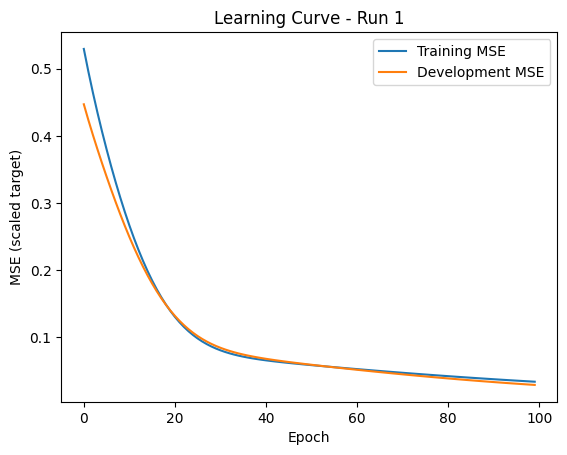

In [17]:

# Plot training and development errors
plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Development MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE (scaled target)")
plt.title("Learning Curve - Run 1")
plt.legend()
plt.show()


In [18]:

# Get the final MSE values
train_mse = history.history["loss"][-1]
val_mse = history.history["val_loss"][-1]

print("Final Training MSE:", train_mse)
print("Final Development MSE:", val_mse)


Final Training MSE: 0.03409333899617195
Final Development MSE: 0.02931227721273899


In [19]:

from sklearn.metrics import mean_squared_error

# Predict the training-target mean for every development row
mean_prediction = np.mean(y_train_scaled)

baseline_predictions = np.full_like(
    y_val_scaled,
    mean_prediction
)

baseline_mse = mean_squared_error(
    y_val_scaled,
    baseline_predictions
)

print("Training-mean predictor MSE:", baseline_mse)
print("Neural network MSE:", val_mse)
print("Neural network beats baseline:", val_mse < baseline_mse)


Training-mean predictor MSE: 0.9386600526195553
Neural network MSE: 0.02931227721273899
Neural network beats baseline: True


In [20]:

# Save the weights learned by our first model
model.save_weights("model_run_1.weights.h5")

print("Run 1 weights saved!")


Run 1 weights saved!


In [21]:

# Set up the seeds for our remaining four runs
seeds = [101, 102, 103, 104]

# Create lists to store results
results = []
histories = []

print("Seeds for remaining runs:", seeds)


Seeds for remaining runs: [101, 102, 103, 104]


In [22]:

from time import perf_counter

results = []
histories = []

for run, seed in enumerate([100, 101, 102, 103, 104], start=1):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    model = build_mlp()

    start_time = perf_counter()

    history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=100,
        batch_size=32,
        shuffle=True,
        verbose=0
    )

    fit_time = perf_counter() - start_time

    val_mse = history.history["val_loss"][-1]

    results.append({
        "Run": run,
        "Seed": seed,
        "Validation_MSE": val_mse,
        "Fit_Time_Seconds": fit_time
    })

    histories.append(history.history)

    model.save_weights(f"model_run_{run}.weights.h5")

    print(f"Run {run} completed!")


Run 1 completed!
Run 2 completed!
Run 3 completed!
Run 4 completed!
Run 5 completed!


In [23]:

# Convert our five results into a table
results_df = pd.DataFrame(results)

# Display the table
display(results_df)


,Run,Seed,Validation_MSE,Fit_Time_Seconds
0,1,100,0.029312,24.731690
1,2,101,0.012783,13.257390
2,3,102,0.026245,12.968971
3,4,103,0.238175,15.108538
4,5,104,0.028125,13.293975


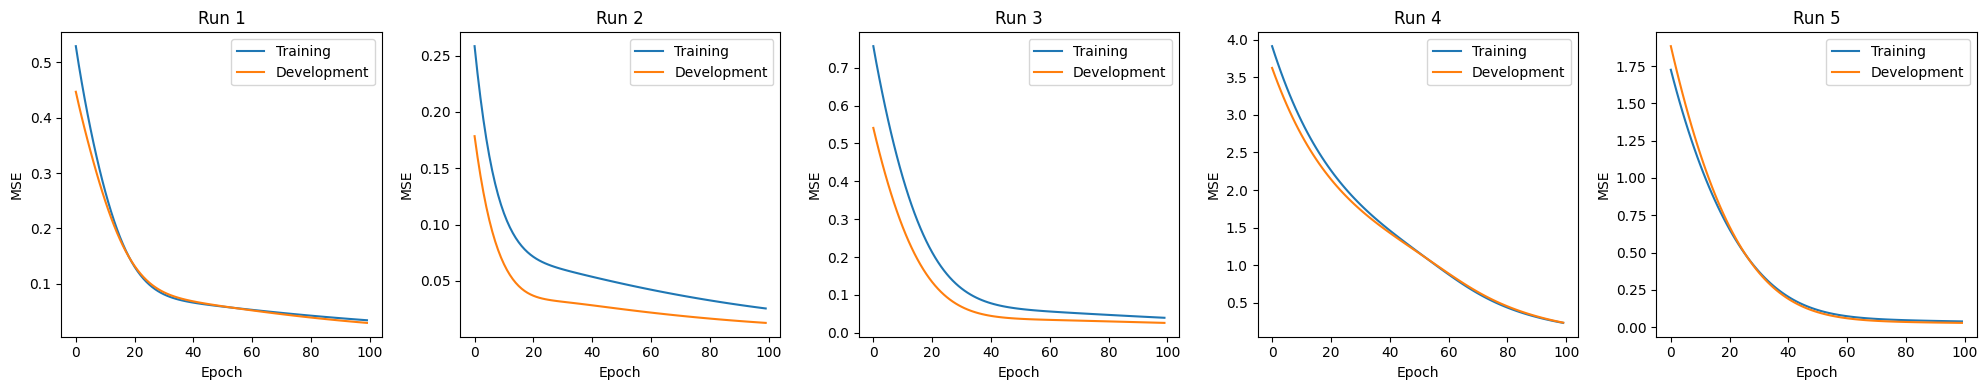

In [24]:

# Display the learning curve for each run
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    axes[i].plot(histories[i]["loss"], label="Training")
    axes[i].plot(histories[i]["val_loss"], label="Development")

    axes[i].set_title(f"Run {i+1}")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE")
    axes[i].legend()

plt.tight_layout()
plt.show()


In [25]:

# Save the five learning curves as an image
fig.savefig("five_learning_curves.png", dpi=300, bbox_inches="tight")

# Save the validation results as a CSV file
results_df.to_csv("validation_results.csv", index=False)

print("Learning curves and results saved!")


Learning curves and results saved!


In [26]:

# Repeat Run 2 using the same seed
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(101)

repeat_model = build_mlp()

repeat_history = repeat_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=100,
    batch_size=32,
    shuffle=True,
    verbose=0
)

repeat_mse = repeat_history.history["val_loss"][-1]
original_mse = results_df.loc[
    results_df["Run"] == 2, "Validation_MSE"
].iloc[0]

print("Original Run 2 MSE:", original_mse)
print("Repeated Run 2 MSE:", repeat_mse)
print("Absolute difference:", abs(original_mse - repeat_mse))


Original Run 2 MSE: 0.012782914564013481
Repeated Run 2 MSE: 0.012782914564013481
Absolute difference: 0.0


In [27]:

# Repeat each run using its original seed
for run, seed in enumerate([100, 101, 102, 103, 104], start=1):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    repeat_model = build_mlp()

    repeat_history = repeat_model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=100,
        batch_size=32,
        shuffle=True,
        verbose=0
    )

    repeated_mse = repeat_history.history["val_loss"][-1]
    original_mse = results_df.loc[
        results_df["Run"] == run, "Validation_MSE"
    ].iloc[0]

    difference = abs(original_mse - repeated_mse)

    print(f"Run {run}: Difference = {difference:.10f}")


Run 1: Difference = 0.0000000000
Run 2: Difference = 0.0000000000
Run 3: Difference = 0.0000000000
Run 4: Difference = 0.0000000000
Run 5: Difference = 0.0000000000


In [28]:

import json

# Record our experiment settings
config = {
    "dataset": "linear_synthetic",
    "samples": 500,
    "features": feature_names,
    "data_seed": 42,
    "data_hash": data_hash,
    "split": [0.6, 0.2, 0.2],
    "split_seed": 42,
    "hidden_units": 4,
    "activation": "tanh",
    "output_activation": "linear",
    "optimizer": "adam",
    "loss": "mse",
    "epochs": 100,
    "batch_size": 32,
    "refit_seeds": [100, 101, 102, 103, 104]
}

with open("experiment_config.json", "w") as file:
    json.dump(config, file, indent=4)

print("Experiment configuration saved!")


Experiment configuration saved!


In [29]:

from pathlib import Path

# Show the files saved in Colab
for file in sorted(Path(".").glob("*")):
    if file.is_file():
        print(file.name)


experiment_config.json
five_learning_curves.png
model_run_1.weights.h5
model_run_2.weights.h5
model_run_3.weights.h5
model_run_4.weights.h5
model_run_5.weights.h5
split_manifest.csv
validation_results.csv


In [30]:

# Save the dataset and its audit results
df.to_csv("dataset.csv", index=False)

audit = pd.DataFrame([{
    "rows": len(df),
    "features": len(feature_names),
    "missing_values": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated(subset=feature_names + ["target"]).sum()),
    "data_hash": data_hash
}])

audit.to_csv("dataset_audit.csv", index=False)

display(audit)


,rows,features,missing_values,duplicate_rows,data_hash
0,500,3,0,0,51c7b8568680f66ad915d2673c9f4d027d9a7b23af6fa1...


In [31]:

# Create a fresh model to document its architecture
summary_model = build_mlp()

# Save the model summary to a text file
with open("model_summary.txt", "w") as file:
    summary_model.summary(
        print_fn=lambda line: file.write(line + "\n")
    )

print("Model summary saved!")
summary_model.summary()


Model summary saved!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21 (84.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:

# Save the learning history of each model
for i in range(5):
    history_df = pd.DataFrame(histories[i])

    history_df.to_csv(
        f"learning_history_run_{i+1}.csv",
        index=False
    )

print("All five learning histories saved!")


All five learning histories saved!


In [33]:

import zipfile
from google.colab import files

# Collect all Phase 1 experiment files
file_names = [
    "dataset.csv",
    "dataset_audit.csv",
    "split_manifest.csv",
    "experiment_config.json",
    "model_summary.txt",
    "validation_results.csv",
    "five_learning_curves.png"
]

file_names += [
    f"model_run_{i}.weights.h5" for i in range(1, 6)
]

file_names += [
    f"learning_history_run_{i}.csv" for i in range(1, 6)
]

# Create a ZIP file
with zipfile.ZipFile("phase1_results.zip", "w") as zip_file:
    for name in file_names:
        zip_file.write(name)

# Download the ZIP file
files.download("phase1_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:

import joblib

# Save the scalers fitted on training data
joblib.dump(feature_scaler, "feature_scaler.joblib")
joblib.dump(target_scaler, "target_scaler.joblib")

print("Both scalers saved!")


Both scalers saved!


In [35]:

# Add both scalers to our existing ZIP file
with zipfile.ZipFile("phase1_results.zip", "a") as zip_file:
    zip_file.write("feature_scaler.joblib")
    zip_file.write("target_scaler.joblib")

# Download the updated ZIP
files.download("phase1_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>